In [ ]:
import os
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models.feature_extraction import create_feature_extractor

from tqdm import tqdm

In [ ]:
!gdown "1I5Of433HE2etWS49klL0Zwp1DHd122wa"

Downloading...
From (original): https://drive.google.com/uc?id=1I5Of433HE2etWS49klL0Zwp1DHd122wa
From (redirected): https://drive.google.com/uc?id=1I5Of433HE2etWS49klL0Zwp1DHd122wa&confirm=t&uuid=b650a470-c33f-4b0f-9b6e-861263050d45
To: /content/Cleaned_OurDataSet.zip
100% 2.42G/2.42G [00:28<00:00, 84.7MB/s]


In [ ]:
!unzip -q "/content/Cleaned_OurDataSet.zip"

In [ ]:
import shutil
import os

# Your original 4 folders
folder_to_delete = '/content/Cleaned_OurDataSet/Alticini'
folder_to_delete2 = '/content/Cleaned_OurDataSet/Miridae'
folder_to_delete3 = '/content/Cleaned_OurDataSet/lytta polita'
folder_to_delete4 = '/content/Cleaned_OurDataSet/Locustoidea'

# The 5 new low-performing/low-support conflict classes
# Note: Handled space/underscore variations to match your exact directory names
folder_to_delete5 = '/content/Cleaned_OurDataSet/Armyworm_butterfly'
folder_to_delete6 = '/content/Cleaned_OurDataSet/sawfly_caterpillar'
folder_to_delete7 = '/content/Cleaned_OurDataSet/cerodonta denticornis_butterfly'
folder_to_delete8 = '/content/Cleaned_OurDataSet/large cutworm_caterpillar'
folder_to_delete9 = '/content/Cleaned_OurDataSet/yellow cutworm_caterpillar'

# List of all target paths for a clean execution loop
all_targets = [
    folder_to_delete, folder_to_delete2, folder_to_delete3, folder_to_delete4]

print("Starting clean-up operation...")
deleted_count = 0

for target_path in all_targets:
    if os.path.exists(target_path):
        shutil.rmtree(target_path)
        print(f"❌ Successfully deleted: {os.path.basename(target_path)}")
        deleted_count += 1
    else:
        # Fallback check: try switching underscores to spaces or vice versa if a folder isn't found
        base = os.path.basename(target_path)
        alt_base = base.replace('_', ' ') if '_' in base else base.replace(' ', '_')
        alt_path = os.path.join(os.path.dirname(target_path), alt_base)

        if os.path.exists(alt_path):
            shutil.rmtree(alt_path)
            print(f"❌ Successfully deleted (variant match): {alt_base}")
            deleted_count += 1
        else:
            print(f"⚠️ Skipped (Folder not found on disk): {base}")

print(f"\nDone! Permanently removed {deleted_count} high-conflict class folders from your base dataset.")

Starting clean-up operation...
❌ Successfully deleted: Alticini
❌ Successfully deleted: Miridae
❌ Successfully deleted: lytta polita
❌ Successfully deleted: Locustoidea

Done! Permanently removed 4 high-conflict class folders from your base dataset.


In [ ]:
!pip install split-folders

In [ ]:
len(os.listdir('/content/dataset_split/train'))

63

In [ ]:
import os
from PIL import Image
import imagehash

source_dataset_dir = "/content/beforeCleanDataset"
unique_hashes = set()
delete_count = 0

print("🧹 Starting global deduplication...")

for root, _, files in os.walk(source_dataset_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            file_path = os.path.join(root, file)
            try:
                with Image.open(file_path) as img:
                    # Generate structural fingerprint
                    h = str(imagehash.phash(img))

                if h in unique_hashes:
                    # If we've seen this exact image structure before, remove it
                    os.remove(file_path)
                    delete_count += 1
                else:
                    unique_hashes.add(h)
            except Exception:
                continue

print(f"✅ Deduplication complete! Purged {delete_count} exact duplicate images.")

ModuleNotFoundError: No module named 'imagehash'

In [ ]:
import splitfolders

# input_folder: the path where your 12 class folders are
# output_folder: where the train/val/test folders will be created
splitfolders.ratio("/content/Cleaned_OurDataSet", output="/content/dataset_split",
                   seed=42, ratio=(.8, .1, .1), move=False)

Copying files: 107897 files [00:41, 2613.56 files/s]


# **Step 1: Setup and Environment**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 2: Define the WaveLet + MobileNet

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import torch.optim as optim

class HaarDWT2D(nn.Module):
    """Lossless 2D Haar Wavelet Decomposition."""
    def __init__(self):
        super(HaarDWT2D, self).__init__()
        self.register_buffer('pL', torch.tensor([0.5, 0.5]))
        self.register_buffer('pH', torch.tensor([0.5, -0.5]))

    def forward(self, x):
        B, C, H, W = x.shape
        x_grouped = x.view(B * C, 1, H, W)

        k_LL = torch.outer(self.pL, self.pL).view(1, 1, 2, 2)
        k_LH = torch.outer(self.pL, self.pH).view(1, 1, 2, 2)
        k_HL = torch.outer(self.pH, self.pL).view(1, 1, 2, 2)
        k_HH = torch.outer(self.pH, self.pH).view(1, 1, 2, 2)

        kernels = torch.cat([k_LL, k_LH, k_HL, k_HH], dim=0).to(x.device)
        sub_bands = nn.functional.conv2d(x_grouped, kernels, stride=2)
        sub_bands = sub_bands.view(B, C, 4, H // 2, W // 2)

        # Output has C * 4 channels (12 channels for RGB input)
        out = sub_bands.permute(0, 1, 2, 3, 4).reshape(B, C * 4, H // 2, W // 2)
        return out

class WaveletEnhancedMobileNet(nn.Module):
    def __init__(self, num_classes=10):
        super(WaveletEnhancedMobileNet, self).__init__()

        self.dwt = HaarDWT2D()

        # Pre-encoder: Projects 12 frequency channels back to 3 channels
        # so our pretrained MobileNet backbone can interpret it natively.
        self.frequency_projector = nn.Sequential(
            nn.Conv2d(in_channels=12, out_channels=3, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(3),
            nn.ReLU(inplace=True)
        )

        # Load untouched, optimized MobileNetV2
        self.backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

        # Swap out classifier head
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier[1] = nn.Linear(in_features, num_classes)

    def forward(self, x):
        x_freq = self.dwt(x)                          # Lossless downsample to 112x112
        x_encoded = self.frequency_projector(x_freq) # Encode into high-signal 3-channel map
        out = self.backbone(x_encoded)
        return out



In [ ]:
# Instantiate model
model = WaveletEnhancedMobileNet(num_classes=68).to(device)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 93.5MB/s]


# **Step 4: Data Augmentation and Loading**

In [ ]:
# Simple Gaussian Noise
class AddGaussianNoise(object):
    def __init__(self, mean=0., std=1.):
        self.std = std
        self.mean = mean
    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

# Exact same methods proposed by paper
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # Image normalization
    transforms.RandomHorizontalFlip(), # Basic
    transforms.RandomRotation([0, 270]), # Spin
    # transforms.ColorJitter(brightness=0.2, contrast=0.2), # Color jitter
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), # Zoom simulation
    # AddGaussianNoise(0., 0.1), # Gaussian noise
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Assuming dataset is organized in class folders
train_dataset = datasets.ImageFolder('/content/dataset_split/train', transform=train_transforms)
val_dataset = datasets.ImageFolder('/content/dataset_split/val', transform=val_transforms)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

In [ ]:
import os
import torch
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import Dataset, DataLoader
from collections import Counter
import random

# 1. Custom Gaussian Noise Transform (Kept from your setup)
class AddGaussianNoise(object):
    def __init__(self, mean=0., std=1.):
        self.std = std
        self.mean = mean
    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

# 2. Define standard vs. augmentation transforms
# Base transform applied to ALL images (even high classes) for normalization
base_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Selective augmentation applied ONLY to lower classes
only_lower_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), # Pure Crop/Zoom
    transforms.ToTensor(),
    AddGaussianNoise(0., 0.05),                         # Pure Gaussian Noise
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Custom Dataset Wrapper for Selective Lower-Class Augmentation
class SelectiveAugmentationDataset(Dataset):
    def __init__(self, base_dataset, target_count=2500):
        self.base_dataset = base_dataset
        self.target_count = target_count

        # Group indices by their class label
        self.class_to_indices = {}
        for idx, target in enumerate(self.base_dataset.targets):
            if target not in self.class_to_indices:
                self.class_to_indices[target] = []
            self.class_to_indices[target].append(idx)

        self.num_classes = len(self.class_to_indices)
        print(f"Verified: Processing {self.num_classes} classes.")

        # Build virtual mapping
        self.virtual_samples = []
        for class_id, indices in self.class_to_indices.items():
            current_count = len(indices)

            if current_count >= self.target_count:
                # HIGH CLASS: Keep original indices, do not flag for augmentation
                for idx in indices:
                    self.virtual_samples.append((idx, False, class_id))
            else:
                # LOW CLASS: Keep originals, then pad up to target_count with augmentation flags
                for idx in indices:
                    self.virtual_samples.append((idx, False, class_id))

                needed = self.target_count - current_count
                for _ in range(needed):
                    random_idx = random.choice(indices)
                    self.virtual_samples.append((random_idx, True, class_id))

    def __len__(self):
        return len(self.virtual_samples)

    def __getitem__(self, index):
        base_idx, should_augment, class_id = self.virtual_samples[index]

        # Load the raw PIL image from ImageFolder directly bypassing its internal transform
        path, _ = self.base_dataset.samples[base_idx]
        img = self.base_dataset.loader(path)

        if should_augment:
            # Applies Crop + Noise ONLY if it's an up-sampled copy of a lower class
            img_tensor = only_lower_aug(img)
        else:
            # Applies clean normalization for native high/low class images
            img_tensor = base_transforms(img)

        return img_tensor, class_id

# 4. Initialize Data Setup
# Load dataset with NO transform applied at the root level to let our wrapper handle it
raw_train_dataset = datasets.ImageFolder('/content/dataset_split/train', transform=None)

# Wrap it: Set target_count to 2500 (brings all 72 classes up to at least 2500 images)
balanced_train_dataset = SelectiveAugmentationDataset(raw_train_dataset, target_count=2500)

val_dataset = datasets.ImageFolder('/content/dataset_split/val', transform=base_transforms)

# 5. Final Loaders (You can safely use shuffle=True here normally)
train_loader = DataLoader(balanced_train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

Verified: Processing 68 classes.


# **Step 5: Training Setup**

In [ ]:
criterion = nn.CrossEntropyLoss()

custom_head_params = []
backbone_pretrained_params = []

for name, param in model.named_parameters():
    if 'frequency_projector' in name or 'classifier' in name:
        custom_head_params.append(param)
    else:
        backbone_pretrained_params.append(param)

# Stabilize the network by balancing learning rates
optimizer = optim.Adam([
    {'params': backbone_pretrained_params, 'lr': 1e-4}, # Safe fine-tuning rate for MobileNet
    {'params': custom_head_params, 'lr': 1e-3}          # Higher rate for new wavelet feature mapping
])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2)

# **Step 6: Training and Evaluation Loops**

In [ ]:
from tqdm.notebook import tqdm
import time

def train_model(model, train_loader, val_loader, epochs=6):
    best_acc = 0.0
    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    print('Training begins...')
    for epoch in range(epochs):
        start_time = time.time()

        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Create a progress bar for the training loader
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", unit="batch")

        for inputs, labels in train_pbar:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

            # Show the current loss in the progress bar
            train_pbar.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100 * correct_train / total_train

        # --- Validation Phase ---
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        # Optional: Add a second progress bar for validation (disappears after finish)
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", unit="batch", leave=False)

        with torch.no_grad():
            for inputs, labels in val_pbar:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)

                # --- Calculate Validation Loss ---
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)
                # ---------------------------------

                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(val_loader.dataset)
        val_acc = 100 * correct_val / total_val

        # Update Learning Rate
        scheduler.step(val_acc)

        # Save History
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)

        epoch_duration = time.time() - start_time
        print(f'Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Val Acc: {val_acc:.2f}% | Time: {epoch_duration:.0f}s')

        # Save Best Model
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_pcsa_model.pth')

    return history

In [ ]:
# Launch training
history = train_model(model, train_loader, val_loader, epochs=10)

Training begins...


Epoch 1/10 [Train]:   0%|          | 0/5313 [00:00<?, ?batch/s]

Epoch 1/10 [Val]:   0%|          | 0/337 [00:00<?, ?batch/s]

Epoch 1/10 | Loss: 1.0927 | Train Acc: 68.63% | Val Acc: 84.63% | Time: 688s


Epoch 2/10 [Train]:   0%|          | 0/5313 [00:00<?, ?batch/s]

Epoch 2/10 [Val]:   0%|          | 0/337 [00:00<?, ?batch/s]

... (19 outputs left out)

Epoch 9/10 [Train]:   0%|          | 0/5313 [00:00<?, ?batch/s]

Epoch 9/10 [Val]:   0%|          | 0/337 [00:00<?, ?batch/s]

Epoch 9/10 | Loss: 0.1272 | Train Acc: 95.39% | Val Acc: 93.39% | Time: 696s


Epoch 10/10 [Train]:   0%|          | 0/5313 [00:00<?, ?batch/s]

# **Step 7: Visualization (Graph Types)**

In [ ]:
def plot_training_history(history):
    epochs = range(1, len(history['train_loss']) + 1)

    # Create a figure with two subplots side-by-side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # --- Plot 1: Accuracy ---
    ax1.plot(epochs, history['train_acc'], label='Training Accuracy', color='blue', lw=2)
    ax1.plot(epochs, history['val_acc'], label='Validation Accuracy', color='red', linestyle='--', lw=2)
    ax1.set_title('Training and Validation Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy (%)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # --- Plot 2: Loss ---
    ax2.plot(epochs, history['train_loss'], label='Training Loss', color='blue', lw=2)
    ax2.plot(epochs, history['val_loss'], label='Validation Loss', color='red', linestyle='--', lw=2)
    ax2.set_title('Training and Validation Loss')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss Value')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

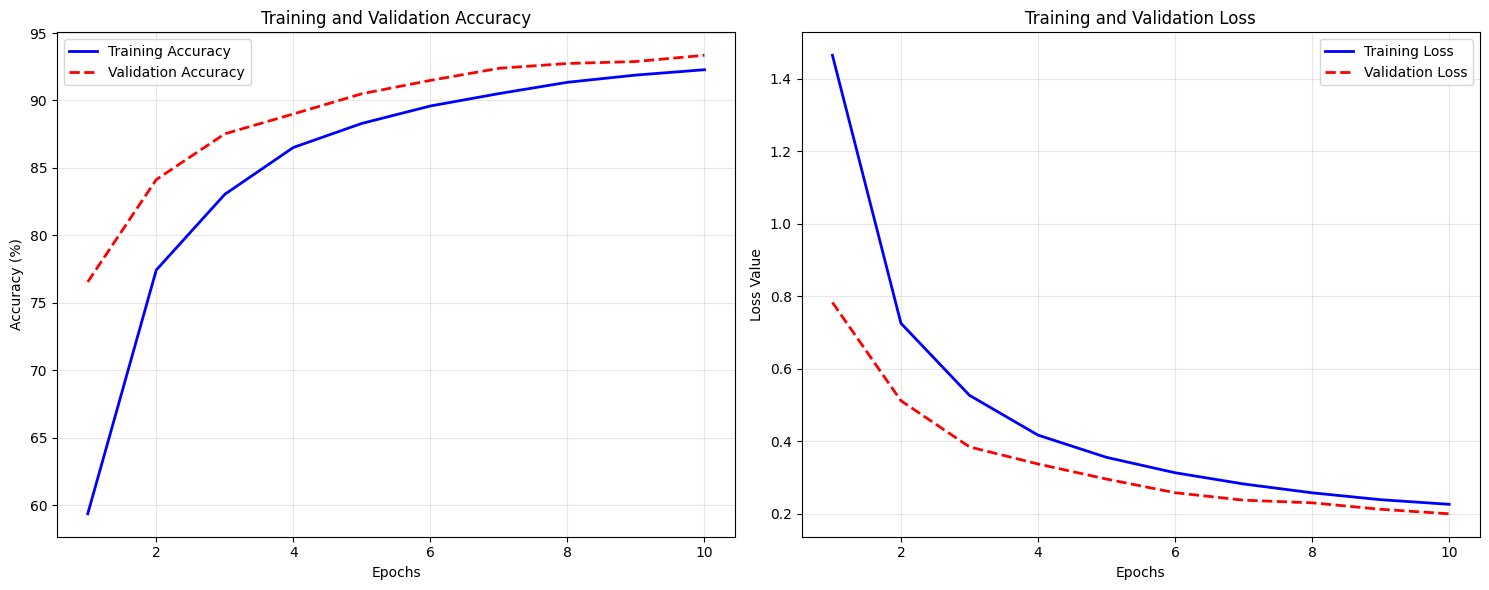

In [ ]:
plot_training_history(history)

# **Step 8: Confusion Matrix and Scoring**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_final_model(model, test_loader, class_names):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Detailed Scoring (P, R, F1) [cite: 180]
    print("\nClassification Report (Precision, Recall, F1):")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix for 12 Classes')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

In [ ]:
import seaborn as sns

# Create the test loader
test_dataset = datasets.ImageFolder('/content/dataset_split/test', transform=val_transforms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# Get the class names directly from the dataset
class_names = test_dataset.classes


Classification Report (Precision, Recall, F1):
                           precision    recall  f1-score   support

        Acalymma_vittatum       0.99      1.00      0.99       411
          Achatina_fulica       1.00      1.00      1.00       465
              Ampelophaga       1.00      1.00      1.00       507
Leptinotarsa_decemlineata       1.00      1.00      1.00       500
      Potosiabre vitarsis       1.00      1.00      1.00       478
                   Thrips       1.00      0.99      1.00       417
              grasshopper       1.00      1.00      1.00       328
              leaf beetle       0.99      0.99      0.99       514
    legume blister beetle       1.00      1.00      1.00       531
             lytta polita       1.00      0.99      0.99       487

                 accuracy                           1.00      4638
                macro avg       1.00      1.00      1.00      4638
             weighted avg       1.00      1.00      1.00      4638



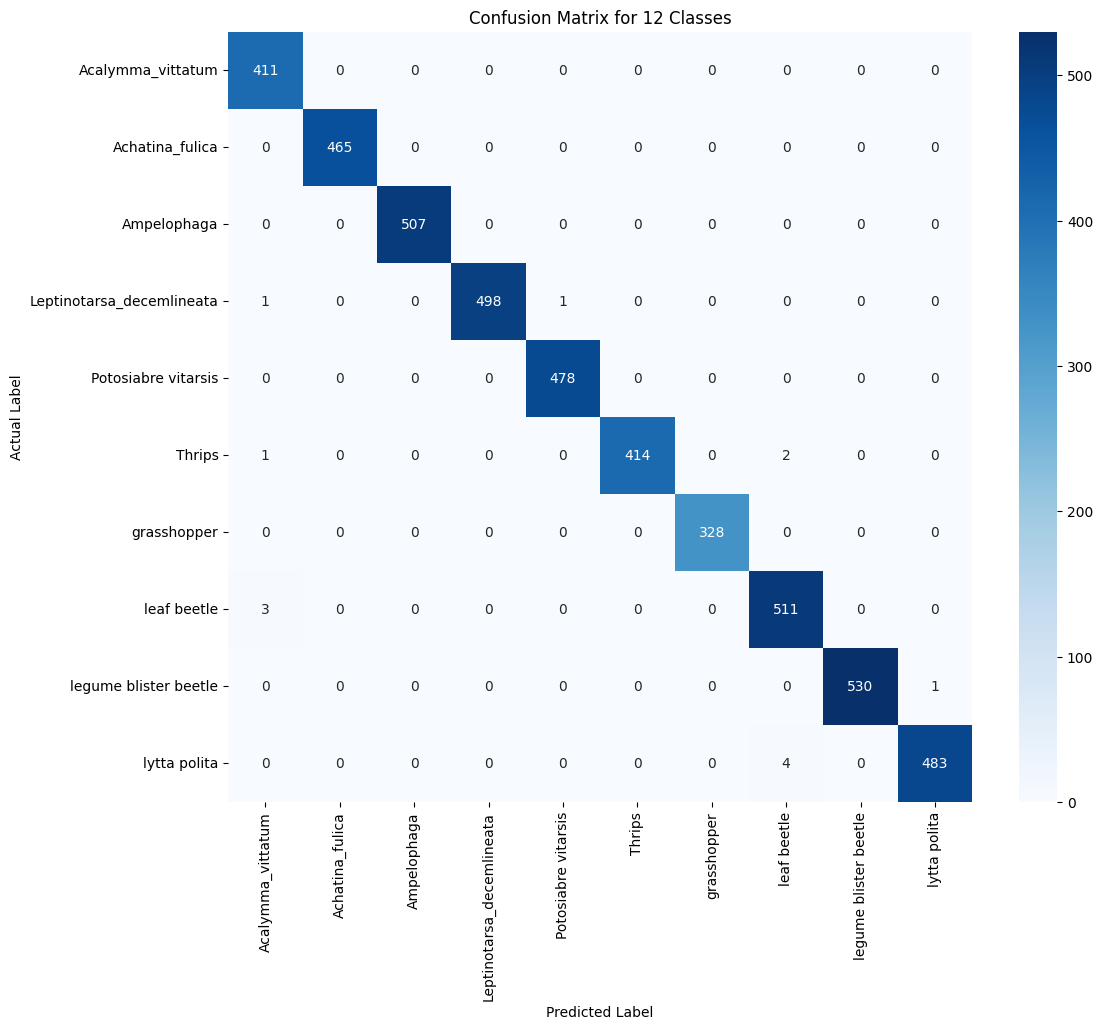

In [ ]:
evaluate_final_model(model, test_loader, class_names)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_massive_model(model, test_loader, class_names):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Standard text classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Compute raw confusion matrix (counts)
    cm = confusion_matrix(y_true, y_pred)

    # 1. HUGE canvas size to physically separate 79 classes
    fig, ax = plt.subplots(figsize=(45, 35))

    # 2. Plot with tiny text and zero spacing borders
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',          # Keeps raw numbers. Change to '.2f' if using normalized cm
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.1,    # Adds a very thin line between cells to visually separate them
        linecolor='lightgray',
        annot_kws={"size": 7, "weight": "bold"}, # Makes internal numbers tiny but sharp
        cbar_kws={'shrink': 0.5} # Prevents the colorbar from dominating the height
    )

    # 3. Style the Title and Axis Labels
    plt.title('Complete Confusion Matrix (79 Classes)', fontsize=28, pad=30)
    plt.ylabel('Actual Label', fontsize=22)
    plt.xlabel('Predicted Label', fontsize=22)

    # 4. Rotate labels and shrink text so 79 words fit alongside each other
    plt.xticks(rotation=90, ha='center', fontsize=7) # 90 degrees vertical is best for 79 items
    plt.yticks(rotation=0, fontsize=7)

    plt.tight_layout()

    # 5. CRITICAL: Save as a high-res file.
    # Your Jupyter/IDE window will scale this down, making it look blurry.
    # Open this saved file directly on your computer and zoom in to read it perfectly!
    plt.savefig('massive_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.savefig('massive_confusion_matrix.pdf', bbox_inches='tight') # PDF is infinitely zoomable

    plt.show()


Classification Report:
                                   precision    recall  f1-score   support

                Acalymma_vittatum       0.99      0.99      0.99       218
                  Achatina_fulica       0.99      1.00      0.99       247
                      Ampelophaga       0.99      1.00      1.00       279
                    Anasa_tristis       0.95      0.98      0.96       123
                           Aphids       0.93      0.87      0.90       206
             Armyworm_caterpillar       0.91      0.86      0.89       118
              Aulacophora_similis       0.99      0.99      0.99       186
        Beet spot flies_butterfly       0.91      0.77      0.84        92
      Beet spot flies_caterpillar       0.84      0.80      0.82       198
                Cicadella viridis       0.93      1.00      0.96       269
                     Cicadellidae       0.97      0.83      0.89       294
                       Dermaptera       0.99      1.00      1.00       208


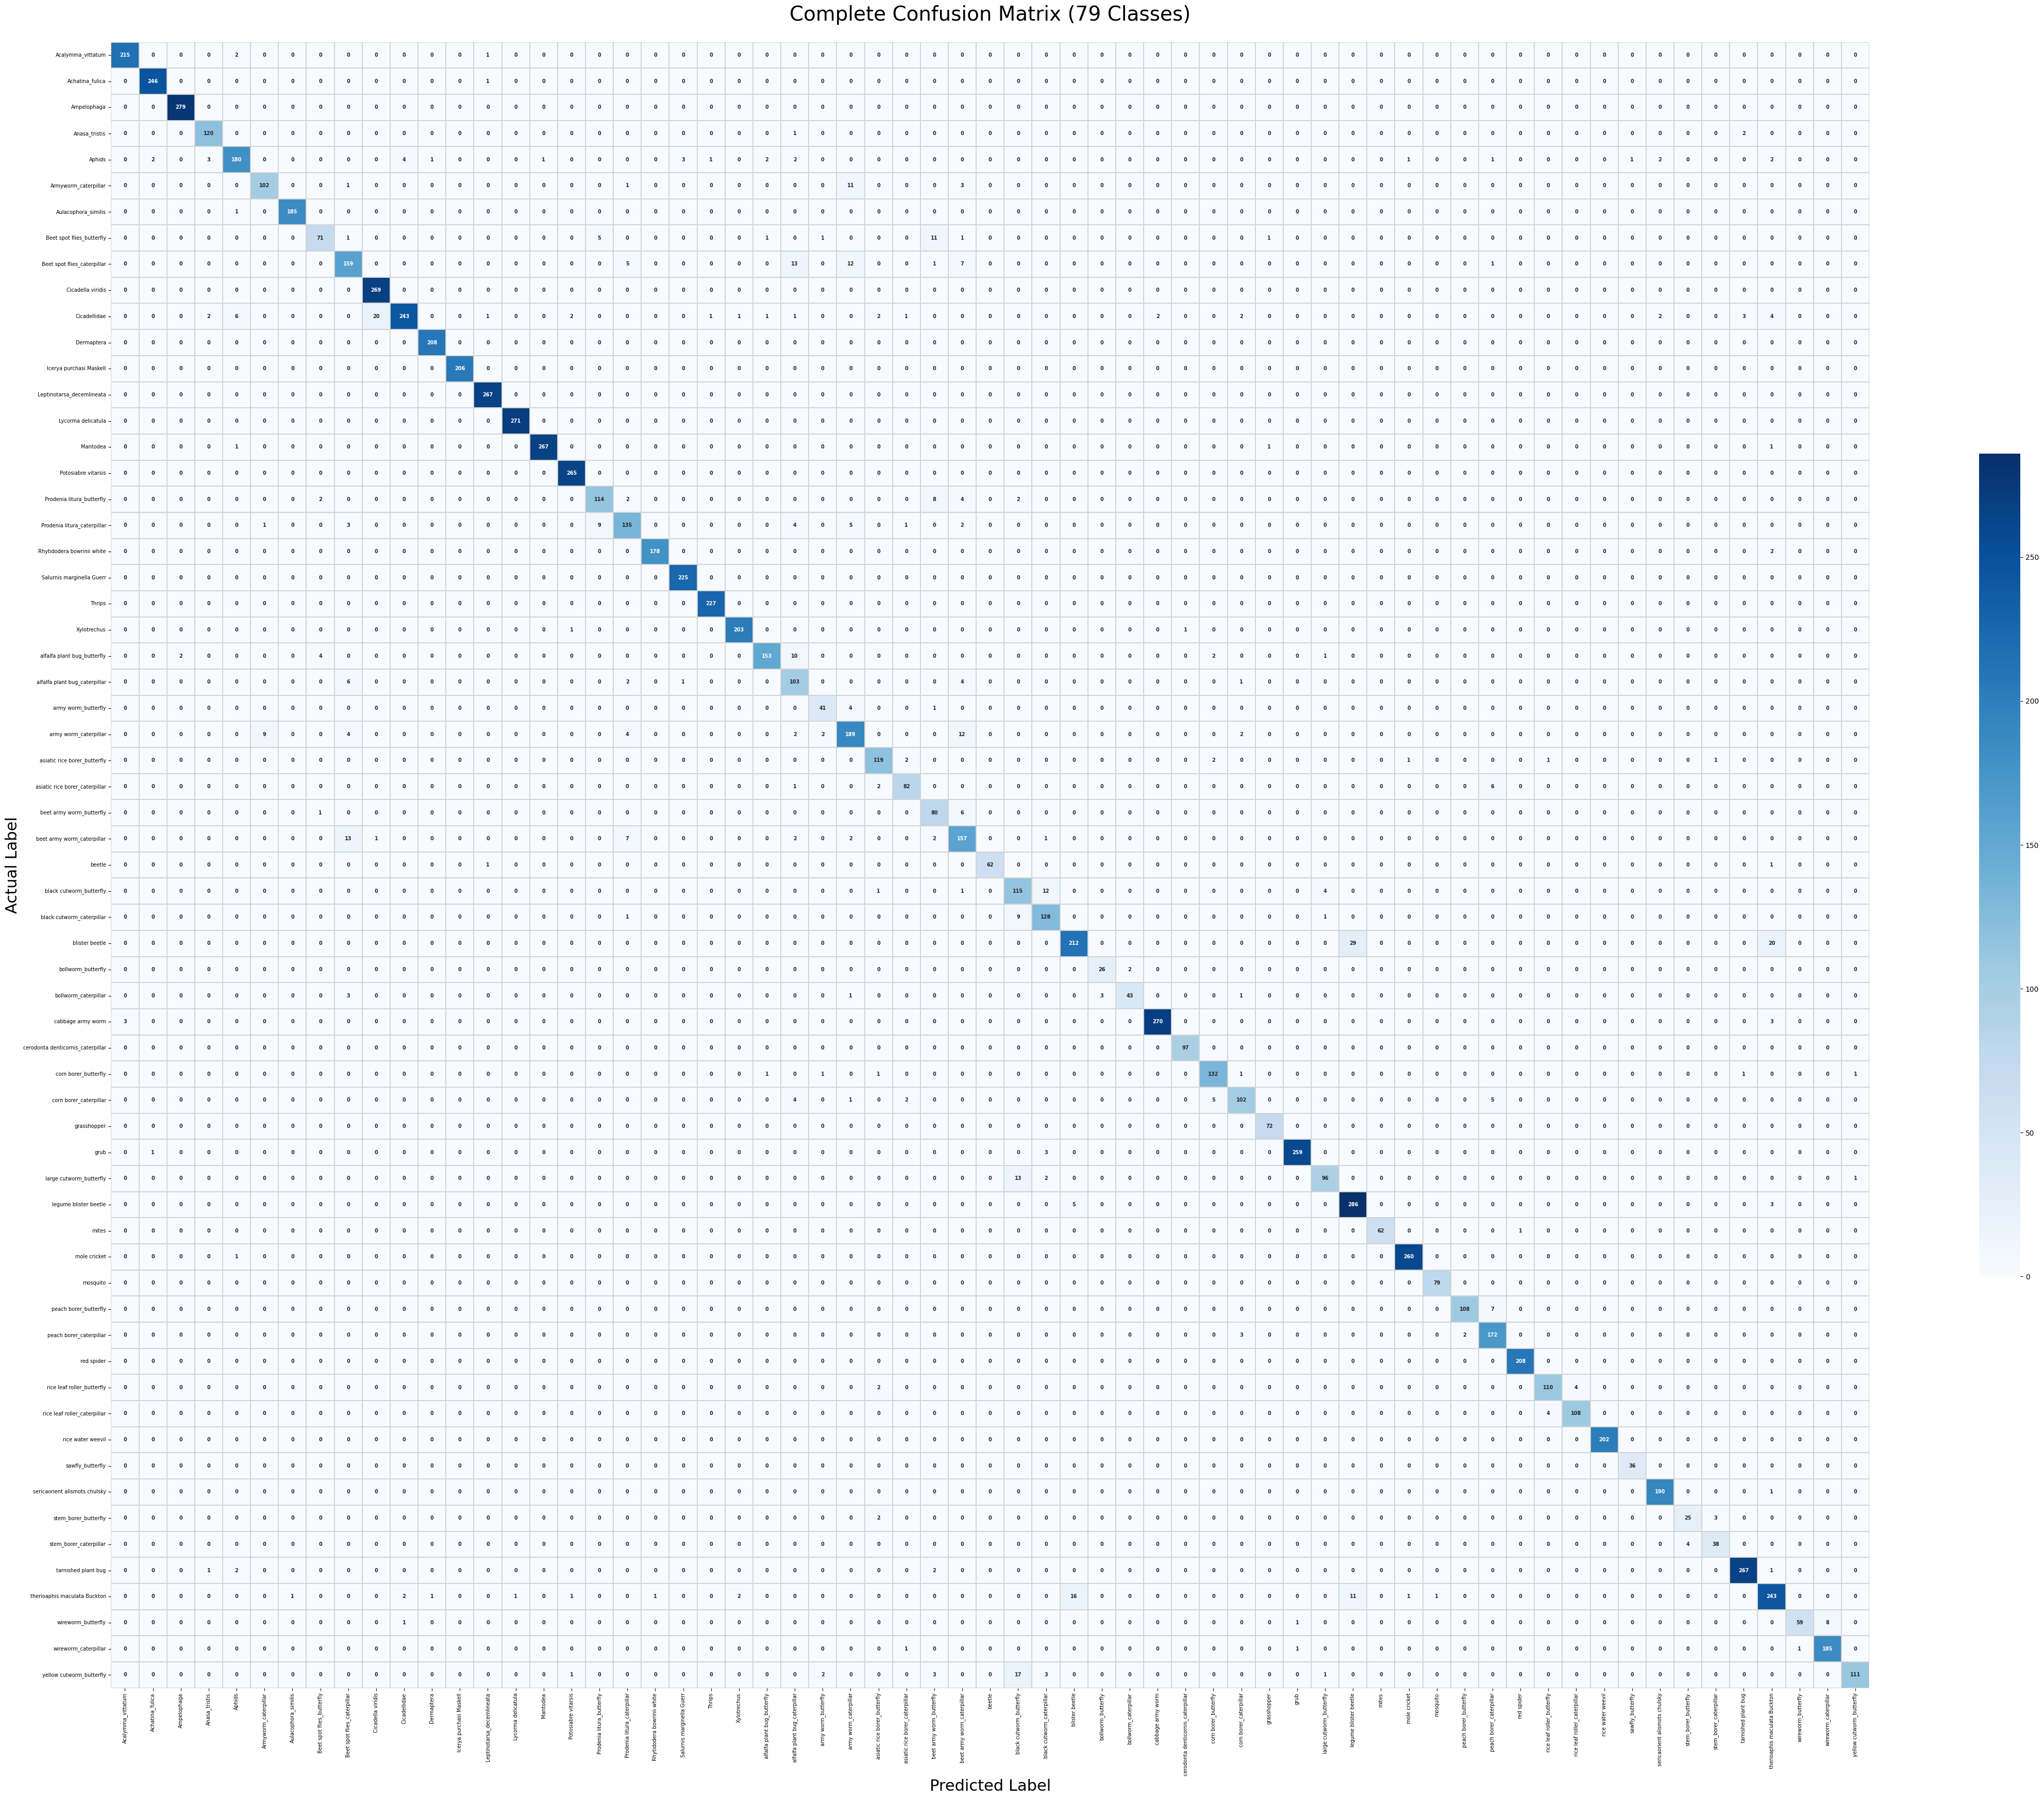

In [ ]:
evaluate_massive_model(model, test_loader, class_names)

In [ ]:
import cv2
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handlers = []
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]

        # Register execution observers on the chosen structural feature block
        self.handlers.append(self.target_layer.register_forward_hook(forward_hook))
        self.handlers.append(self.target_layer.register_full_backward_hook(backward_hook))

    def generate_heatmap(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        self.model.zero_grad()
        loss = output[0, target_class]
        loss.backward()

        # Global average pooling of gradients across operational spatial bounds
        gradients = self.gradients.detach().cpu().numpy()[0]
        activations = self.activations.detach().cpu().numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))

        # Perform weighted linear combination of activation maps
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        # Filter out negative configurations via ReLU correction pass
        cam = np.maximum(cam, 0)
        if np.max(cam) != 0:
            cam = cam / np.max(cam)

        return cam, target_class

    def remove_hooks(self):
        for handler in self.handlers:
            handler.remove()

def display_gradcam(image_path, model, target_layer, transform, class_names):
    """Loads an image, visualizes activation distribution, and displays inline output."""
    # Read raw pixel properties using baseline dataset steps
    orig_img = Image.open(image_path).convert('RGB')
    input_tensor = transform(orig_img).unsqueeze(0).to(device)

    # Initialize extraction workflow
    cam_extractor = GradCAM(model, target_layer)
    heatmap, pred_idx = cam_extractor.generate_heatmap(input_tensor)
    cam_extractor.remove_hooks()

    # Resize attention boundaries back to raw dynamic shapes
    heatmap_resized = cv2.resize(heatmap, (orig_img.size[0], orig_img.size[1]))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # Superimpose alpha map values with source spatial arrays
    overlayed_img = np.float32(heatmap_colored) * 0.4 + np.float32(orig_img) * 0.6
    overlayed_img = np.clip(overlayed_img, 0, 255).astype(np.uint8)

    # Render results visually
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(orig_img)
    axes[0].set_title("Original Structural Image")
    axes[0].axis('off')

    predicted_label = class_names[pred_idx] if class_names else f"ID: {pred_idx}"
    axes[1].imshow(overlayed_img)
    axes[1].set_title(f"Grad-CAM Attribution Focus\nPredicted Category: {predicted_label}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

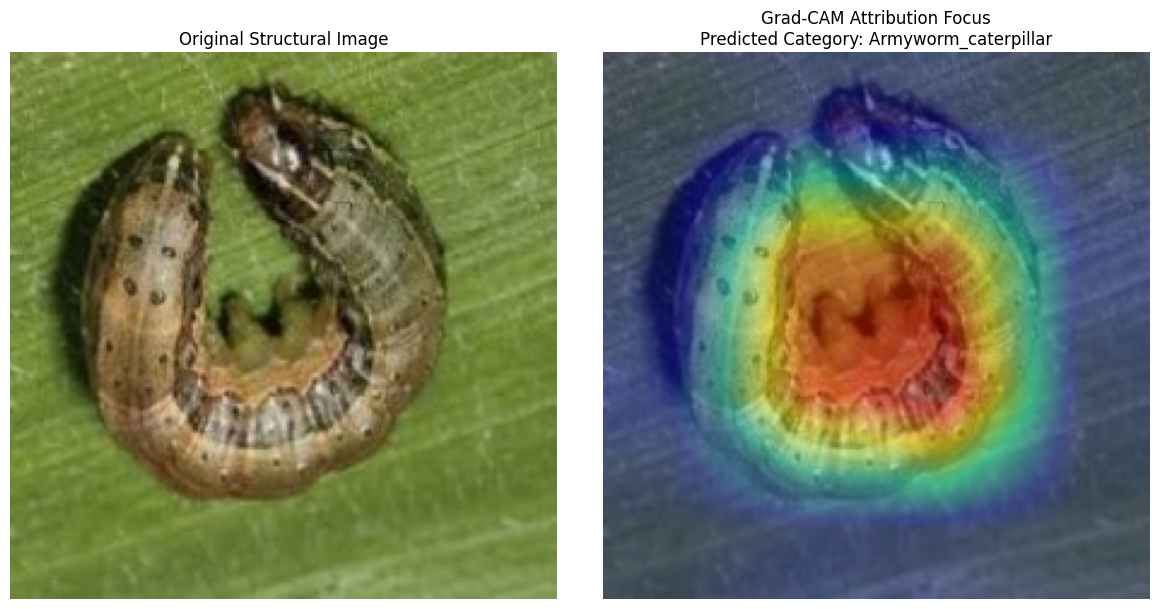

In [ ]:
# Extract category labels explicitly out of standard dataset structure instances
class_labels = train_dataset.classes

# Target the very last operational convolutional layer of the fine-tuned architecture
# For standard models.mobilenet_v2, this matches the final spatial mapping block
target_conv_layer = model.backbone.features[-1]

# Point this to any validation image path within your split folders
sample_target_path = "/content/dataset_split/test/Armyworm_caterpillar/Armyworm_caterpillar_0278.jpg"

try:
    display_gradcam(
        image_path=sample_target_path,
        model=model,
        target_layer=target_conv_layer,
        transform=val_transforms, # Ensures standard size/normalization rules
        class_names=class_labels
    )
except FileNotFoundError:
    print(f"Update sample_target_path with a valid image location from your runtime file tree.")